# 09 · Home advantage: does the crowd change the fight?

**The idea:** a fighter in front of their home crowd might perform better, or get the benefit of the doubt from the judges. That's an "external" factor the fight stats can't see.
This notebook adds **where the fight happens** and **where each fighter is from**, then asks four questions:
1. Do home fighters win more often?
2. Is that the crowd, or just matchmaking? The UFC books locals in favorable fights on home cards.
3. Does it work through **performance** or through **judging**?
4. Does it improve the prediction model?

**Prior work:**
- **Holmes (2022, University of Liverpool),** modeling 1,840 UFC decisions: a home fighter *with a live crowd* gained about **+3.6 percentage points** per judge-round. Without fans, the effect wasn't significant. ([summary](https://agentmma.com/mma-lab/ufc-hometown-judging-bias))
- **A randomized experiment with Muay Thai judges:** live crowd noise shifted their scores by about half a point per bout. ([Myers et al.](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC3442224/))
- **A performance study:** home fighters actually *threw and landed fewer* strikes, with no consistent effect on who wins. ([Fighters Only](https://fightersonly.com/article/ext/91682/UFC/1); [MMA Sucka overview](https://mmasucka.com/news/home-advantage-exist-mma/))

**A possible natural experiment:** from March 2020 to April 2021, COVID put UFC fights in **empty arenas**. If the advantage is the crowd, it should disappear then. (Spoiler: in our data there are too few home fights abroad in that window to tell. See section 4.)

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

from ufc import geo, careers as C, modeling as M, form as F
from ufc.features import MIN_FEATURES, HIST_FEATURES
from ufc.viz import use_style, SERIES, INK_2, NEUTRAL, GRID
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
use_style()

fights = pd.read_parquet("data/processed/fights.parquet")
ff = pd.read_parquet("data/processed/fighter_fights.parquet")
hist = pd.read_parquet("data/processed/elo_history.parquet")
directory = pd.read_parquet("data/processed/fighters.parquet")
origin = pd.read_parquet("data/processed/fighter_origin.parquet")
hf = geo.home_features(ff, fights, origin)
print(f"{len(origin):,} fighters looked up on ESPN · origin found for {origin.found.mean():.0%}")

2,777 fighters looked up on ESPN · origin found for 88%


## 1 · Where fighters are from
Fighter country comes from ESPN's athlete profiles (**citizenship**), matched by name. Fighters who share a name are separated by birth date where ESPN lists one.

**Caveats:**
- Citizenship isn't the same as the crowd's favorite. Israel Adesanya is listed as Nigerian, but his home crowd is New Zealand.
- We have no US state, so a Texan fighting in Texas counts the same as a Texan fighting in New York.

So this measures *country-level* home advantage, which is a conservative test.

,fighters,share
match,,
dob-confirmed,2043,0.736
wikidata,358,0.129
exact-name,323,0.116
NaN,53,0.019


,country,gym,match
name,,,
Charles Oliveira,Brazil,Chute Boxe,dob-confirmed
Alexander Volkanovski,Australia,City Kickboxing,dob-confirmed
Israel Adesanya,Nigeria,NaN,dob-confirmed
Islam Makhachev,Russia,Eagles MMA,dob-confirmed
Conor McGregor,Ireland,SBG Ireland,dob-confirmed
Georges St-Pierre,Canada,TriStar Gym,wikidata
Jose Aldo,Brazil,Nova Uniao,dob-confirmed
Max Holloway,USA,Gracie Technics,dob-confirmed
Khabib Nurmagomedov,Russia,AKA (American Kickboxing Academy),dob-confirmed


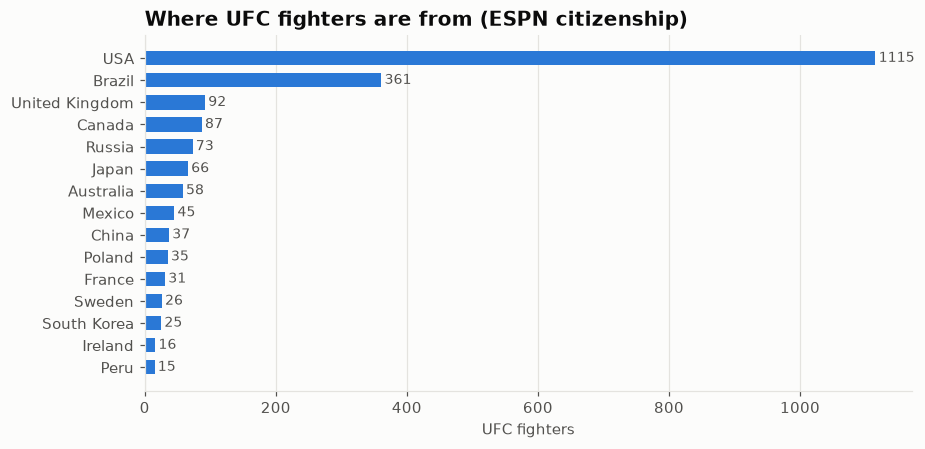

In [2]:
m = origin.match.value_counts(dropna=False)
display(pd.DataFrame({"fighters": m, "share": (m / len(origin)).round(3)}))
spot = ["Charles Oliveira", "Alexander Volkanovski", "Israel Adesanya", "Islam Makhachev", "Conor McGregor", "Georges St-Pierre",
        "Jose Aldo", "Max Holloway", "Khabib Nurmagomedov", "Leon Edwards", "Tai Tuivasa", "Brandon Moreno", "Zhang Weili",
        "Jiri Prochazka", "Kamaru Usman"]
display(origin.set_index("name").reindex(spot)[["country", "gym", "match"]])
top = origin.country.value_counts().head(15)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(top.index[::-1], top.values[::-1], color=SERIES[0], height=0.65)
for i, v in enumerate(top.values[::-1]):
    ax.text(v + 5, i, str(v), va="center", fontsize=9, color=INK_2)
ax.grid(axis="y", visible=False); ax.set_xlabel("UFC fighters"); ax.set_title("Where UFC fighters are from (ESPN citizenship)")
plt.show()

In [3]:
t = fights.assign(event_country=fights.location.map(geo.event_country))
ev = t.drop_duplicates("event")
unk = ev[ev.event_country.isna()]
print(f"event country parsed for {ev.event_country.notna().mean():.1%} of {len(ev)} events" + (f" · unparsed: {unk.location.tolist()[:5]}" if len(unk) else ""))
print("empty-arena events:", ev[ev.date.between(geo.EMPTY_FROM, geo.EMPTY_TO)].shape[0],
      f"({geo.EMPTY_FROM:%Y-%m-%d} → {geo.EMPTY_TO:%Y-%m-%d})")

# one row per fight with both fighters' home status (only fights where we know both origins)
side = hf.merge(ff[["fight_id", "fighter", "corner", "result", "date", "method_group"]], on=["fight_id", "fighter"])
w = side.pivot_table(index="fight_id", columns="corner", values=["home", "same_continent", "travel"], aggfunc="first")
w.columns = [f"{'r' if c == 'Red' else 'b'}_{v}" for v, c in w.columns]
bouts = fights.set_index("fight_id")[["date", "event", "location", "winner", "method", "method_group", "r_fighter", "b_fighter"]].join(w)
bouts["event_country"] = bouts.location.map(geo.event_country)
bouts["crowd"] = ~bouts.date.between(geo.EMPTY_FROM, geo.EMPTY_TO)
bouts["home_diff"] = bouts.r_home - bouts.b_home
both_known = bouts.r_home.notna() & bouts.b_home.notna()
one_home = both_known & (bouts.home_diff != 0) & bouts.winner.isin(["Red", "Blue"])
bouts["home_won"] = np.where(bouts.home_diff > 0, bouts.winner == "Red", bouts.winner == "Blue")
hv = bouts[one_home & (bouts.date >= "2005-01-01")].copy()
print(f"fights with both origins known: {both_known.mean():.0%} · home-vs-away fights since 2005: {len(hv):,}")
pd.crosstab(hv.event_country, hv.crowd.map({True: "with fans", False: "empty arena"})).sort_values("with fans", ascending=False).head(12)

event country parsed for 100.0% of 793 events
empty-arena events: 47 (2020-03-14 → 2021-04-17)


fights with both origins known: 92% · home-vs-away fights since 2005: 3,627


crowd,empty arena,with fans
event_country,,
USA,144,2284
Brazil,9,351
Canada,0,230
United Kingdom,0,165
Australia,0,129
Mexico,0,57
China,0,56
Japan,0,34
France,0,31


## 2 · Raw home advantage
Fights where **exactly one** fighter is at home: how often does the home fighter win?

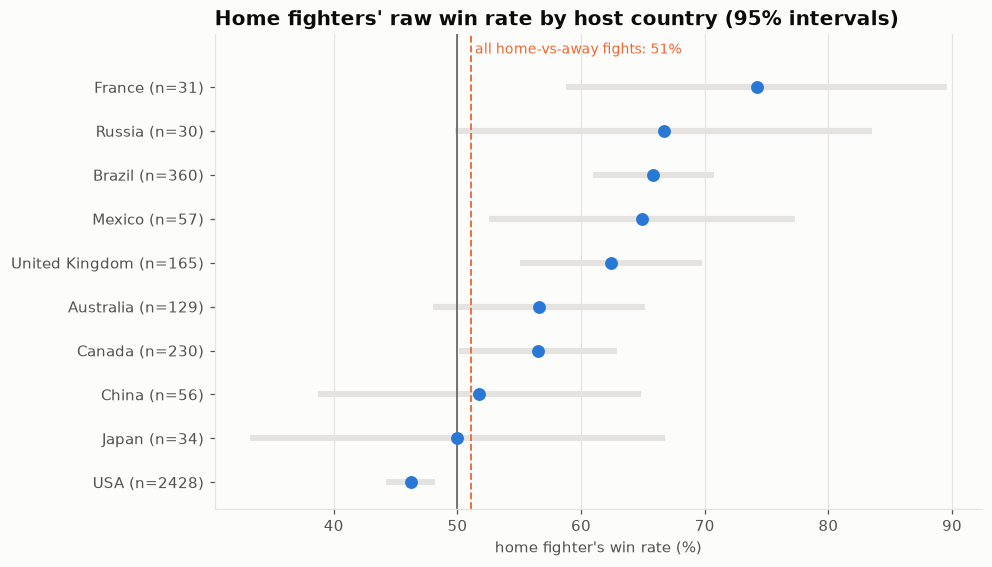

,home_win_rate,lo,hi,fights
all home-vs-away fights,0.511,0.495,0.527,3627.0
events in the USA,0.462,0.442,0.482,2428.0
events outside the USA,0.610,0.582,0.637,1199.0


In [4]:
def rate(s):
    p, n = s.mean(), len(s)
    se = np.sqrt(p * (1 - p) / n) if n else np.nan
    return pd.Series({"home_win_rate": p, "lo": p - 1.96 * se, "hi": p + 1.96 * se, "fights": n})

overall = rate(hv.home_won.astype(float))
by_country = hv.groupby("event_country").home_won.apply(lambda s: rate(s.astype(float))).unstack()
by_country = by_country[by_country.fights >= 30].sort_values("home_win_rate")
in_usa = hv.groupby(hv.event_country.eq("USA").map({True: "events in the USA", False: "events outside the USA"})).home_won.apply(lambda s: rate(s.astype(float))).unstack()

fig, ax = plt.subplots(figsize=(9, 0.42 * len(by_country) + 1.4))
y = np.arange(len(by_country))
ax.hlines(y, by_country.lo * 100, by_country.hi * 100, color=GRID, lw=4)
ax.scatter(by_country.home_win_rate * 100, y, color=SERIES[0], s=55, zorder=3)
ax.axvline(50, color=INK_2, lw=1); ax.axvline(overall.home_win_rate * 100, color=SERIES[1], lw=1.2, ls="--")
ax.set_yticks(y, [f"{c} (n={int(n)})" for c, n in zip(by_country.index, by_country.fights)]); ax.grid(axis="y", visible=False)
ax.set_xlabel("home fighter's win rate (%)"); ax.set_title("Home fighters' raw win rate by host country (95% intervals)")
ax.set_ylim(-0.6, len(by_country) + 0.2)
ax.text(overall.home_win_rate * 100, len(by_country) - 0.15, f" all home-vs-away fights: {overall.home_win_rate:.0%}", color=SERIES[1], fontsize=9, va="center")
plt.show()
display(pd.concat([overall.to_frame("all home-vs-away fights").T, in_usa]).round(3))

## 3 · Crowd or matchmaking?
Raw win rates mix two things:
- **the crowd effect;**
- **matchmaking:** promoters book local fighters against beatable opponents on home cards to sell tickets.

The fix from notebook 06 is to compare results with each fighter's **Elo expectation** (result minus expected win chance). Matchmaking is already built into the expectation: if a local is booked against a weaker opponent, their expected chance is higher. So a positive "home surprise" means home fighters do better than their ratings say *given who they're facing*.

,fights,expected win %,actual win %,result − Elo expectation (pp),lo,hi
all,3649.0,50.7,51.1,0.4,-1.2,2.0
with fans,3492.0,50.7,51.4,0.7,-1.0,2.3
empty arena,157.0,50.1,44.6,-5.5,-13.3,2.2
"with fans, outside USA",1198.0,51.8,60.9,9.1,6.3,11.8
"with fans, in USA",2294.0,50.2,46.4,-3.7,-5.7,-1.7


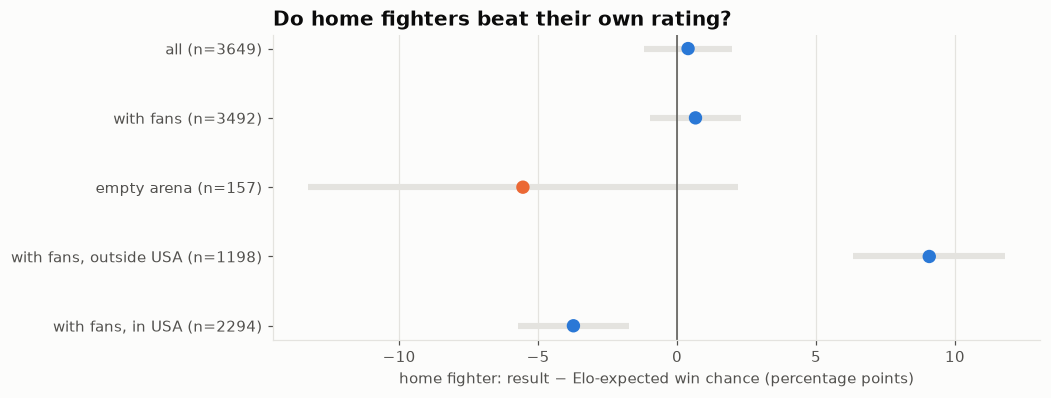

In [5]:
perf = C.per_fight_perf(ff, hist)
pv = perf.merge(hf[["fight_id", "fighter", "home", "crowd", "event_country"]], on=["fight_id", "fighter"])
pv = pv.merge(bouts[["home_diff"]], left_on="fight_id", right_index=True)
pv = pv[(pv.date >= "2005-01-01") & pv.elo_surprise.notna()]
mixed = pv[pv.home_diff.abs() == 1]                    # exactly one fighter at home
home_rows = mixed[mixed.home == 1]

def surprise(s):
    m, se = s.mean(), s.std() / np.sqrt(len(s))
    return pd.Series({"result − Elo expectation (pp)": m * 100, "lo": (m - 1.96 * se) * 100, "hi": (m + 1.96 * se) * 100,
                      "expected win %": np.nan, "fights": len(s)})

rows = {}
for label, d in [("all", home_rows), ("with fans", home_rows[home_rows.crowd == 1]), ("empty arena", home_rows[home_rows.crowd == 0]),
                 ("with fans, outside USA", home_rows[(home_rows.crowd == 1) & (home_rows.event_country != "USA")]),
                 ("with fans, in USA", home_rows[(home_rows.crowd == 1) & (home_rows.event_country == "USA")])]:
    r = surprise(d.elo_surprise)
    r["expected win %"] = (d.score - d.elo_surprise).mean() * 100
    r["actual win %"] = d.score.mean() * 100
    rows[label] = r
adj = pd.DataFrame(rows).T[["fights", "expected win %", "actual win %", "result − Elo expectation (pp)", "lo", "hi"]]
display(adj.round(1))

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(adj))[::-1]
ax.hlines(y, adj.lo, adj.hi, color=GRID, lw=4)
ax.scatter(adj.iloc[:, 3], y, color=[SERIES[0], SERIES[0], SERIES[1], SERIES[0], SERIES[0]], s=60, zorder=3)
ax.axvline(0, color=INK_2, lw=1)
ax.set_yticks(y, [f"{i} (n={int(n)})" for i, n in zip(adj.index, adj.fights)]); ax.grid(axis="y", visible=False)
ax.set_xlabel("home fighter: result − Elo-expected win chance (percentage points)")
ax.set_title("Do home fighters beat their own rating?")
plt.show()

**Reading this:**
- **Outside the USA, the home edge is real and survives the matchmaking correction.** Home fighters win about 9 points more often than their own ratings predict.
- **Inside the USA, "home" fighters do *worse* than their ratings.** That isn't a crowd effect. Almost every American is "home" at every US event, so "home in the USA" really means "American vs a foreign fighter". Foreigners who make it onto UFC cards in the US are a selected group: they travelled, were signed as prospects, and are often underrated by a 1500 starting Elo.
  So the single "home" feature mixes two different things, and the model has to keep them apart.
- The overall "empty arena" row mixes US and non-US events; section 4 compares like with like.

In [6]:
# is the edge abroad changing over time?
abroad = home_rows[(home_rows.event_country != "USA") & (home_rows.crowd == 1)].copy()
abroad["era"] = pd.cut(abroad.date.dt.year, [2004, 2014, 2019, 2023, 2030], labels=["2005–14", "2015–19", "2021–23", "2024+"])
era_tab = abroad.groupby("era", observed=True).elo_surprise.agg(["mean", "sem", "size"])
era_tab = pd.DataFrame({"fights": era_tab["size"], "home edge vs Elo (pp)": era_tab["mean"] * 100,
                        "lo": (era_tab["mean"] - 1.96 * era_tab["sem"]) * 100, "hi": (era_tab["mean"] + 1.96 * era_tab["sem"]) * 100})
display(era_tab.round(1))

,fights,home edge vs Elo (pp),lo,hi
era,,,,
2005–14,348,10.2,5.2,15.3
2015–19,521,6.9,2.7,11.1
2021–23,96,17.7,8.4,26.9
2024+,233,8.8,2.5,15.0


## 4 · Performance or judging?
If the crowd helps through **judging**, the home edge should show up in **decisions**, especially split decisions, and not in knockouts.

**Scorecard test:** fit a model of *which fighter a judge's card goes to*, using only what happened in the fight: significant strikes, knockdowns, takedowns and control time (red minus blue). Then ask whether home fighters get more cards than their in-fight numbers earn, with fans vs without.

In [7]:
# 4a: how the fight ended when one fighter was home
hv["ending"] = np.select([hv.method.str.contains("Split", na=False), hv.method.str.contains("Majority", na=False),
                          hv.method_group == "DEC", hv.method_group == "KO/TKO", hv.method_group == "SUB"],
                         ["split decision", "majority decision", "unanimous decision", "KO/TKO", "submission"], "other")
end = hv[hv.ending != "other"].groupby(["ending", hv.crowd.map({True: "with fans", False: "empty arena"})]).home_won.agg(["mean", "size"]).unstack()
display((end["mean"] * 100).round(1).join(end["size"], rsuffix=" n").rename(columns=lambda c: f"{c} (home win %)" if " n" not in str(c) else c))

crowd,empty arena (home win %),with fans (home win %),empty arena n,with fans n
ending,,,,
KO/TKO,47.1,49.0,51,1171
majority decision,100.0,48.0,1,25
split decision,75.0,51.5,12,342
submission,34.4,50.7,32,641
unanimous decision,39.7,53.8,58,1285


In [8]:
# 4b: judge cards vs in-fight stats
js = pd.read_parquet("data/processed/judge_scores.parquet")
js = js[js.r_score != js.b_score].copy()
js["card_red"] = (js.r_score > js.b_score).astype(int)
st = fights.set_index("fight_id")
for c in ["sig_str", "kd", "td", "ctrl_sec"]:
    js[f"{c}_d"] = js.fight_id.map(st[f"r_{c}"] - st[f"b_{c}"])
js = js.join(bouts[["home_diff", "crowd", "date", "event_country"]], on="fight_id").dropna(subset=["sig_str_d", "kd_d", "td_d", "ctrl_sec_d"])
js = js[js.date >= "2005-01-01"]
X = js[["sig_str_d", "kd_d", "td_d", "ctrl_sec_d"]] / js[["sig_str_d", "kd_d", "td_d", "ctrl_sec_d"]].std()
stats_only = LogisticRegression(max_iter=1000).fit(X, js.card_red)
js["p_stats"] = stats_only.predict_proba(X)[:, 1]
print(f"{len(js):,} judge cards in {js.fight_id.nunique():,} decisions · the in-fight stats alone pick the judge's winner "
      f"{((js.p_stats > .5) == js.card_red).mean():.0%} of the time")

# cards in home-vs-away fights, from the home fighter's point of view
h = js[js.home_diff.abs() == 1].copy()
h["home_card"] = np.where(h.home_diff > 0, h.card_red, 1 - h.card_red)
h["home_expected"] = np.where(h.home_diff > 0, h.p_stats, 1 - h.p_stats)
def card_bias(d):
    resid = d.home_card - d.home_expected
    se = resid.std() / np.sqrt(len(d))
    return pd.Series({"cards": len(d), "home share of cards %": d.home_card.mean() * 100,
                      "expected from stats %": d.home_expected.mean() * 100,
                      "bias (pp)": resid.mean() * 100, "lo": (resid.mean() - 1.96 * se) * 100, "hi": (resid.mean() + 1.96 * se) * 100})
jb = pd.DataFrame({"with fans": card_bias(h[h.crowd]), "empty arena": card_bias(h[~h.crowd]),
                   "with fans, outside USA": card_bias(h[h.crowd & (h.event_country != "USA")])}).T
display(jb.round(1))

11,905 judge cards in 3,997 decisions · the in-fight stats alone pick the judge's winner 82% of the time


,cards,home share of cards %,expected from stats %,bias (pp),lo,hi
with fans,4933.0,52.7,51.8,1.0,-0.0,2.0
empty arena,218.0,42.2,45.0,-2.8,-8.2,2.7
"with fans, outside USA",1663.0,60.3,55.7,4.6,2.9,6.3


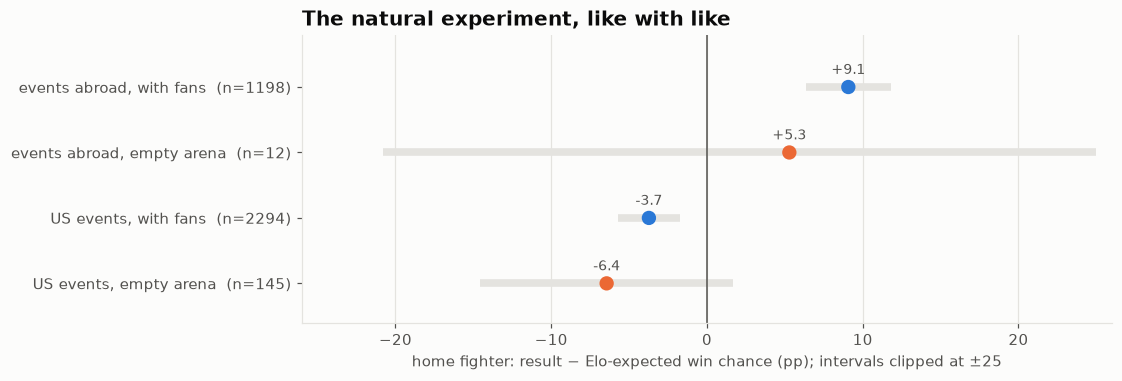

In [9]:
# the natural experiment, compared like with like: US events vs events abroad, fans vs empty arenas
grp = home_rows.assign(where=np.where(home_rows.event_country == "USA", "US events", "events abroad"),
                       fans=np.where(home_rows.crowd == 1, "with fans", "empty arena"))
ne = grp.groupby(["where", "fans"]).elo_surprise.agg(["mean", "sem", "size"])
ne = pd.DataFrame({"fights": ne["size"], "edge": ne["mean"] * 100, "lo": (ne["mean"] - 1.96 * ne["sem"]) * 100,
                   "hi": (ne["mean"] + 1.96 * ne["sem"]) * 100}).reindex(
    [("events abroad", "with fans"), ("events abroad", "empty arena"), ("US events", "with fans"), ("US events", "empty arena")])
fig, ax = plt.subplots(figsize=(9.5, 3.4))
y = np.arange(len(ne))[::-1]
ax.hlines(y, ne.lo.clip(-25, 25), ne.hi.clip(-25, 25), color=GRID, lw=5)
ax.scatter(ne.edge, y, s=70, zorder=3, color=[SERIES[0] if f == "with fans" else SERIES[1] for _, f in ne.index])
for yi, (idx, r) in zip(y, ne.iterrows()):
    ax.text(r.edge, yi + 0.2, f"{r.edge:+.1f}", ha="center", fontsize=9, color=INK_2)
ax.axvline(0, color=INK_2, lw=1); ax.set_xlim(-26, 26); ax.set_ylim(-0.6, len(ne) - 0.2)
ax.set_yticks(y, [f"{w}, {f}  (n={int(n)})" for (w, f), n in zip(ne.index, ne.fights)]); ax.grid(axis="y", visible=False)
ax.set_xlabel("home fighter: result − Elo-expected win chance (pp); intervals clipped at ±25")
ax.set_title("The natural experiment, like with like")
plt.show()

**Reading this honestly:** the empty-arena experiment **can't settle the question**.
- The crowd effect lives in events *abroad*, but only **12** home-crowd fights abroad took place without fans: 10 in Brazil, 2 in Abu Dhabi. Their interval spans roughly −20 to +30 points.
- At US events there's no home edge with or without fans, so there's nothing for empty arenas to remove.
- The judging test has the same problem: the 218 empty-arena cards are almost all from US events.

So what supports a *crowd* explanation is the size and consistency of the abroad effect and the judging bias that comes with it (next section), plus the published experiment on crowd noise. It's not a clean natural experiment in our data.

## 5 · Does it improve the prediction model?
Given section 3, the location features are split into the two effects we found:
- **`home_abroad`:** home crowd *outside the USA*, with fans in the arena (red minus blue: +1, 0 or −1);
- **`us_event`:** "home" at a US event, which really captures American vs foreign fighter.

For comparison, the plain `home` flag mixes the two. Same protocol as notebook 07: choose on 2021–23 validation, test once on 2024 onward, with a bootstrap 95% interval for the change in log loss.

In [10]:
t, _ = M.load_model_table(shrink_k=5)
loc = side.pivot_table(index="fight_id", columns="corner", values=["home"], aggfunc="first")
loc.columns = [f"{'r' if c == 'Red' else 'b'}_{v}" for v, c in loc.columns]
t = t.join(loc, on="fight_id")
ec = t.fight_id.map(fights.set_index("fight_id").location.map(geo.event_country))
crowd = (~t.date.between(geo.EMPTY_FROM, geo.EMPTY_TO)).astype(float)
hd = t.r_home - t.b_home
t["home_diff"] = hd
t["home_abroad_diff"] = hd.where(ec != "USA", 0) * crowd
t["us_event_diff"] = hd.where(ec == "USA", 0)
FINAL = M.diffs(MIN_FEATURES + HIST_FEATURES) + M.FLAGS + ["red_corner"] + M.diffs(F.OPP_FEATURES)

VAL = pd.Timestamp("2021-01-01")
tr, va, trall, te = t[t.date < VAL], t[(t.date >= VAL) & (t.date < M.SPLIT)], t[t.date < M.SPLIT], t[t.date >= M.SPLIT]
abroad_te = (te.home_abroad_diff.fillna(0) != 0).values
print(f"home-crowd-abroad fights: validation {int((va.home_abroad_diff.fillna(0) != 0).sum())} of {len(va)} · test {abroad_te.sum()} of {len(te)}")
res, P = {}, {}
for name, cols in [("final model (notebook 07)", FINAL), ("+ plain home flag", FINAL + ["home_diff"]),
                   ("+ home crowd abroad", FINAL + ["home_abroad_diff"]),
                   ("+ home crowd abroad + US-event split", FINAL + ["home_abroad_diff", "us_event_diff"])]:
    pv_ = M.predict(M.fit(M.logistic(), tr, cols), va, cols)
    P[name] = M.predict(M.fit(M.logistic(), trall, cols), te, cols)
    res[name] = {"validation log loss": log_loss(va.red_win, pv_), **{f"test {k}": v for k, v in M.scores(te.red_win, P[name]).items()},
                 "test log loss, home-abroad fights": log_loss(te.red_win[abroad_te], P[name][abroad_te])}
abl = pd.DataFrame(res).T
base = P["final model (notebook 07)"]
abl["Δ test log loss [95%]"] = [""] + [f"{d:+.4f} [{lo:+.4f}, {hi:+.4f}]" for d, lo, hi in (M.bootstrap_delta(te.red_win, P[k], base) for k in list(P)[1:])]
display(abl.round(4))

LOC = ["home_abroad_diff", "us_event_diff"]
full = M.fit(M.logistic(), trall, FINAL + LOC)
coef = pd.Series(full[-1].coef_[0][len(FINAL):len(FINAL) + 2], index=LOC)
display(coef.round(3).rename("standardized coefficient").to_frame())
# what +1 home-abroad does to an even fight, using the fitted (scaled) coefficient
sd = full.named_steps["standardscaler"].scale_[len(FINAL)]
print(f"an even 50/50 fight becomes {1 / (1 + np.exp(-coef['home_abroad_diff'] / sd)):.1%} for the fighter with the home crowd abroad")

home-crowd-abroad fights: validation 90 of 1507 · test 232 of 1475


,validation log loss,test accuracy,test log_loss,test roc_auc,"test log loss, home-abroad fights",Δ test log loss [95%]
final model (notebook 07),0.6440,0.6393,0.6349,0.6940,0.6450,
+ plain home flag,0.6449,0.6393,0.6349,0.6940,0.6451,"-0.0000 [-0.0001, +0.0001]"
+ home crowd abroad,0.6429,0.6386,0.6347,0.6949,0.6474,"-0.0003 [-0.0027, +0.0023]"
+ home crowd abroad + US-event split,0.6415,0.6380,0.6340,0.6962,0.6484,"-0.0010 [-0.0040, +0.0022]"


,standardized coefficient
home_abroad_diff,0.104
us_event_diff,-0.076


an even 50/50 fight becomes 56.6% for the fighter with the home crowd abroad


**Reading the model test:**
- The plain "home" flag does nothing: the effect abroad and the US paradox cancel out.
- Split into **home crowd abroad** and **US event**, the features improve the 2021–23 validation score (0.6440 → 0.6415), which is more than "who they beat" added in notebook 07.
  On the 2024+ test fights the overall change is small and within noise. Only 232 test fights have a home crowd abroad, too few to settle a 0.003 log-loss difference.
- In plain terms, with everything else equal, a home crowd abroad turns a 50/50 fight into about 57/43.
- By our rule (choose on validation, report test honestly), the split features go into the live app model, labeled as a small, uncertain effect.

## Takeaways
1. **The crowd effect is real, outside the USA.** Home fighters beat their own Elo expectation by about **9 points**, after accounting for who they were matched with. The edge shows up in every era since 2005.
2. **The empty-arena test is inconclusive in our data.** Only 12 home-crowd fights abroad happened without fans, which is far too few. The case for "it's the crowd" rests on the judging bias and on published experiments, not on a clean natural experiment here.
3. **Part of it is the judges.** Outside the USA, home fighters get about **4.6 points more scorecards** than their in-fight numbers earn, close to Holmes's +3.6 per judge-round. Unanimous decisions show it too, not just split decisions.
4. **"Home" in the USA means something else.** Americans at US events *underperform* their ratings against foreign fighters, because the foreigners who make US cards are a selected group. That's why one plain "home" feature doesn't work.
5. **For prediction it's a small, honest gain:** better on validation, and neutral to slightly better on test. It's now an input to the app's model, with a "Fighting at home" driver and a fight-location picker on the Predict tab.